In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

### **Spectrogram - Normal**

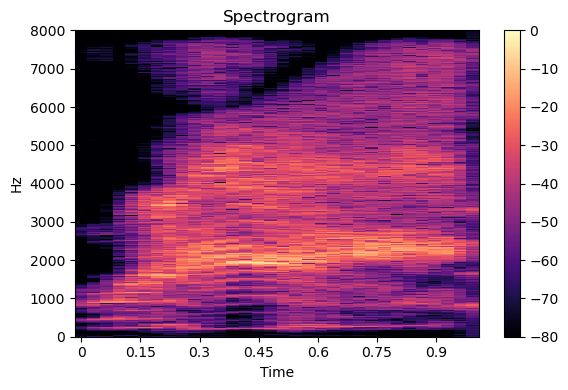

In [ ]:
# Spectrogram 

# audio file path
file_path = "dataset/normal/1 newborn crying_expiration.wav"

# load audio
y, sr = librosa.load(file_path, sr=None)

# create spectrogram
D = librosa.stft(y)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# plot
plt.figure(figsize=(6,4))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar()
plt.title("Spectrogram")
plt.tight_layout()
plt.show()

### **Spectrogram - Sepsis**

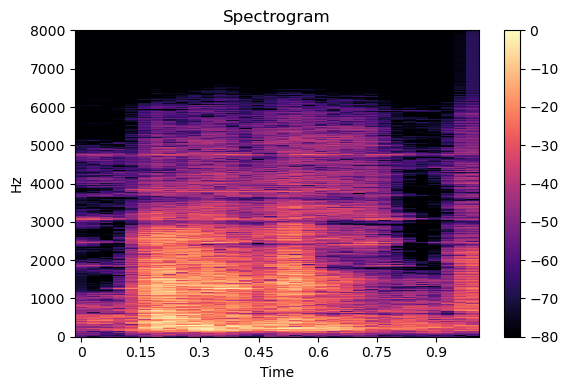

In [26]:
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration2.wav"

# load audio
y, sr = librosa.load(file_path, sr=None)

# create spectrogram
D = librosa.stft(y)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# plot
plt.figure(figsize=(6,4))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar()
plt.title("Spectrogram")
plt.tight_layout()
plt.show()

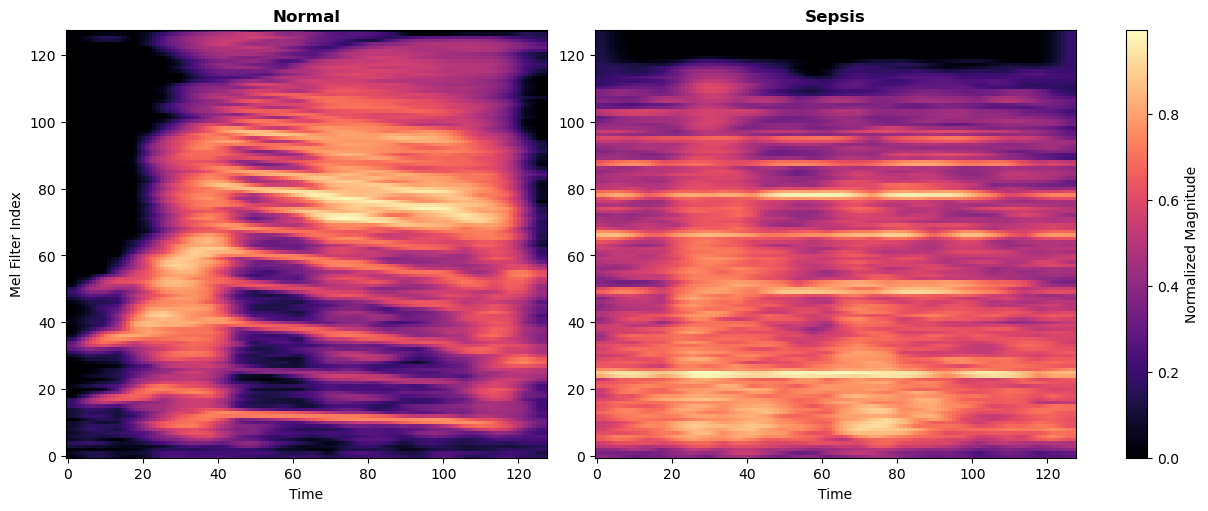

In [157]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import cv2

def get_spectrogram(y, sr):
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    # min-max normalization
    mel_db = (mel_db - np.min(mel_db)) / (np.max(mel_db) - np.min(mel_db) + 1e-6)
    # Resize to fixed size
    mel_db = cv2.resize(mel_db, (128, 128))
    return mel_db

# 1. Load and Generate for both classes
y_n, sr_n = librosa.load("dataset/normal/1 newborn crying_expiration1.wav", sr=16000)
spec_n = get_spectrogram(y_n, sr_n)

y_s, sr_s = librosa.load("dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav", sr=16000)
spec_s = get_spectrogram(y_s, sr_s)

# 2. Create side-by-side Subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# Normal Plot
img1 = ax1.imshow(spec_n, aspect='auto', origin='lower', cmap='magma')
ax1.set_title("Normal", fontweight='bold')
ax1.set_ylabel("Mel Filter Index")
ax1.set_xlabel("Time")

# Sepsis Plot
img2 = ax2.imshow(spec_s, aspect='auto', origin='lower', cmap='magma')
ax2.set_title("Sepsis", fontweight='bold')
ax2.set_xlabel("Time")

# Add a shared colorbar
cbar = fig.colorbar(img1, ax=[ax1, ax2], label='Normalized Magnitude')
# plt.savefig('mel_spectrogram_comparison.pdf', dpi=300)
plt.show()

### **MFCC - Normal**

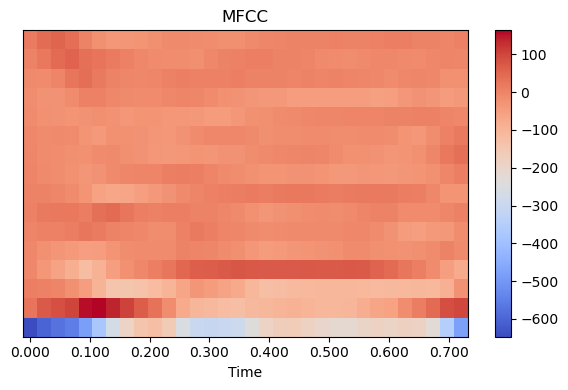

In [58]:
# MFCC (Mel-Frequency Cepstral Coefficients)
# Normal

# audio file path
file_path = "dataset/normal/1 newborn crying_expiration1.wav"

# load audio
y, sr = librosa.load(file_path, sr=None)

# extract MFCC (usually 13–40 coefficients)
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=16)

# plot MFCC
plt.figure(figsize=(6,4))
librosa.display.specshow(mfcc, x_axis='time')
plt.colorbar()
plt.title("MFCC")
plt.tight_layout()
plt.show()

### **MFCC - Sepsis**

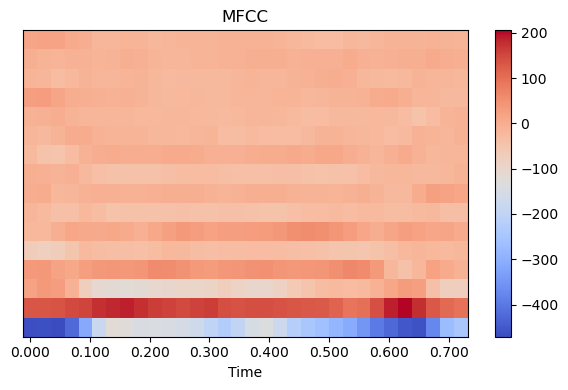

In [53]:
# Sepsis
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration2.wav"

# load audio
y, sr = librosa.load(file_path, sr=None)

# extract MFCC (usually 13–40 coefficients)
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=16)

# plot MFCC
plt.figure(figsize=(6,4))
librosa.display.specshow(mfcc, x_axis='time')
plt.colorbar()
plt.title("MFCC")
plt.tight_layout()
plt.show()

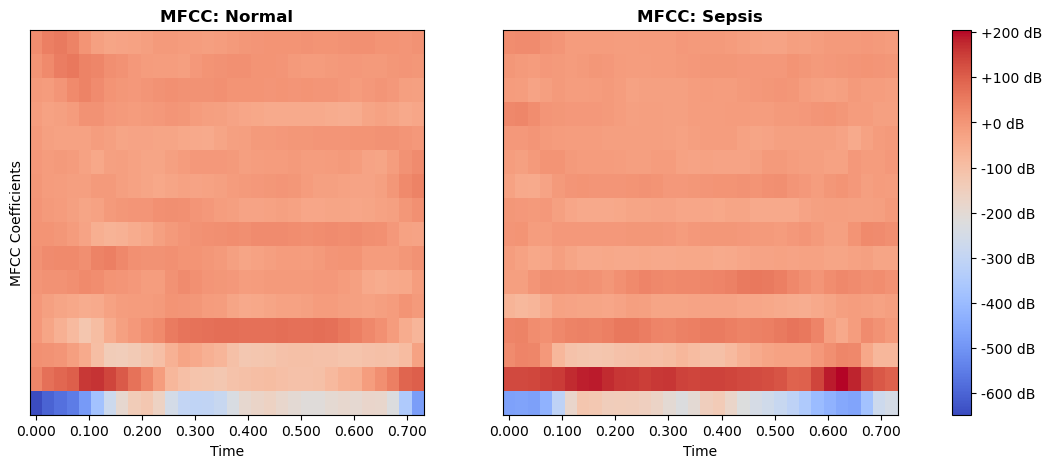

In [59]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load and Extract
y_n, sr_n = librosa.load("dataset/normal/1 newborn crying_expiration1.wav", sr=None)
mfcc_n = librosa.feature.mfcc(y=y_n, sr=sr_n, n_mfcc=16)

y_s, sr_s = librosa.load("dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration2.wav", sr=None)
mfcc_s = librosa.feature.mfcc(y=y_s, sr=sr_s, n_mfcc=16)

# Create Subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Find global min/max for consistent color scaling
v_min = min(mfcc_n.min(), mfcc_s.min())
v_max = max(mfcc_n.max(), mfcc_s.max())

# Plot Normal
img1 = librosa.display.specshow(mfcc_n, x_axis='time', ax=ax1, vmin=v_min, vmax=v_max)
ax1.set_title("MFCC: Normal", fontweight='bold')
ax1.set_ylabel("MFCC Coefficients")

# Plot Sepsis
img2 = librosa.display.specshow(mfcc_s, x_axis='time', ax=ax2, vmin=v_min, vmax=v_max)
ax2.set_title("MFCC: Sepsis", fontweight='bold')

# Shared Colorbar
fig.colorbar(img1, ax=[ax1, ax2], format="%+2.0f dB")
plt.savefig('mfcc_comparison_subplots.pdf', dpi=300)
plt.show()

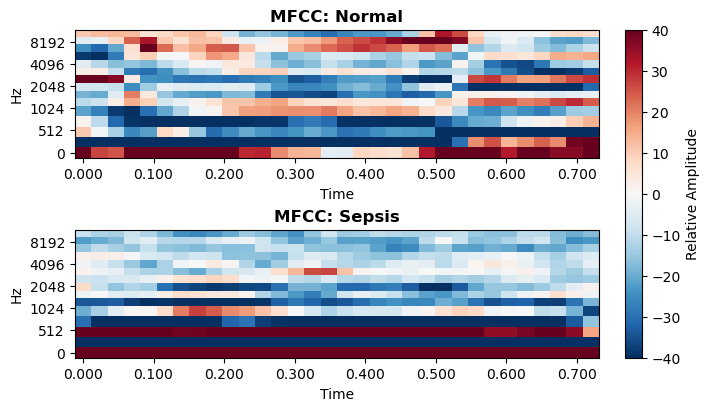

In [110]:
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 1. Load and slice (Removing MFCC 0)
y_n, sr_n = librosa.load("dataset/normal/1 newborn crying_expiration2.wav", sr=None)
mfcc_n = librosa.feature.mfcc(y=y_n, sr=sr_n, n_mfcc=16)[1:, :]

y_s, sr_s = librosa.load("dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav", sr=None)
mfcc_s = librosa.feature.mfcc(y=y_s, sr=sr_s, n_mfcc=16)[1:, :]

# 2. Normalize both to the same range for fair comparison
v_min, v_max = -40, 40 

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 4), constrained_layout=True)

# Normal Plot
img1 = librosa.display.specshow(mfcc_n, x_axis='time', y_axis='mel', 
                                ax=ax1, vmin=v_min, vmax=v_max, cmap='RdBu_r')
ax1.set_title("MFCC: Normal", fontweight='bold')

# Sepsis Plot
img2 = librosa.display.specshow(mfcc_s, x_axis='time', y_axis='mel', 
                                ax=ax2, vmin=v_min, vmax=v_max, cmap='RdBu_r')
ax2.set_title("MFCC: Sepsis", fontweight='bold')

fig.colorbar(img1, ax=[ax1, ax2], label='Relative Amplitude')
# plt.tight_layout()
plt.show()

C:\Users\mdalt\AppData\Local\Temp\ipykernel_47940\3151295578.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


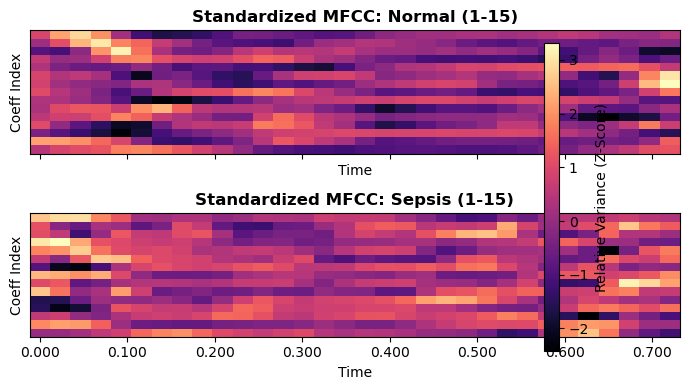

In [68]:
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load and Extract (16 coefficients)
y_n, sr_n = librosa.load("dataset/normal/1 newborn crying_expiration1.wav", sr=None)
mfcc_n = librosa.feature.mfcc(y=y_n, sr=sr_n, n_mfcc=16)[1:, :]

y_s, sr_s = librosa.load("dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration2.wav", sr=None)
mfcc_s = librosa.feature.mfcc(y=y_s, sr=sr_s, n_mfcc=16)[1:, :]

# 2. Standardization (The secret for high-contrast MFCCs)
# This makes the "patterns" pop out
scaler = StandardScaler()
mfcc_n_scaled = scaler.fit_transform(mfcc_n.T).T
mfcc_s_scaled = scaler.fit_transform(mfcc_s.T).T

# 3. Plotting
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 4), sharex=True)

# Normal Plot
img1 = librosa.display.specshow(mfcc_n_scaled, x_axis='time', ax=ax1, cmap='magma')
ax1.set_title("Standardized MFCC: Normal (1-15)", fontweight='bold')
ax1.set_ylabel("Coeff Index")

# Sepsis Plot
img2 = librosa.display.specshow(mfcc_s_scaled, x_axis='time', ax=ax2, cmap='magma')
ax2.set_title("Standardized MFCC: Sepsis (1-15)", fontweight='bold')
ax2.set_ylabel("Coeff Index")

# Single Colorbar for both
fig.colorbar(img1, ax=[ax1, ax2], label='Relative Variance (Z-Score)')

plt.tight_layout()
plt.savefig('mfcc_final_comparison.pdf', dpi=300)
plt.show()

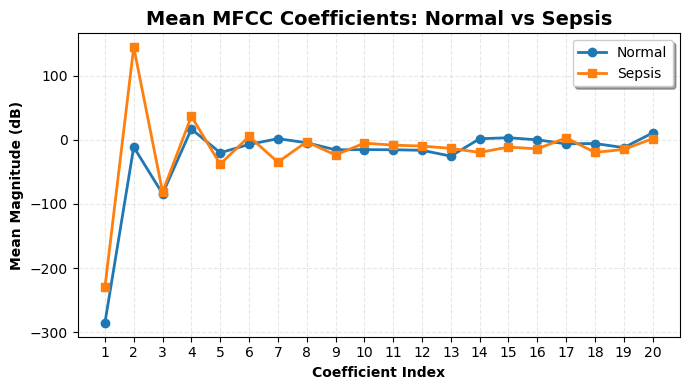

In [48]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load and Extract
y_n, sr_n = librosa.load("dataset/normal/1 newborn crying_expiration1.wav", sr=None)
mfcc_n = librosa.feature.mfcc(y=y_n, sr=sr_n, n_mfcc=20)

y_s, sr_s = librosa.load("dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration1.wav", sr=None)
mfcc_s = librosa.feature.mfcc(y=y_s, sr=sr_s, n_mfcc=20)

# Calculate the mean across time for each of the 20 coefficients
mfcc_mean_n = np.mean(mfcc_n, axis=1)
mfcc_mean_s = np.mean(mfcc_s, axis=1)

plt.figure(figsize=(7, 4))

# Plotting
plt.plot(range(1, 21), mfcc_mean_n, label='Normal', color='#1f77b4', marker='o', linewidth=2)
plt.plot(range(1, 21), mfcc_mean_s, label='Sepsis', color='#ff7f0e', marker='s', linewidth=2)

# Styling
plt.title("Mean MFCC Coefficients: Normal vs Sepsis", fontweight='bold', size=14)
plt.xlabel("Coefficient Index", fontweight='bold')
plt.ylabel("Mean Magnitude (dB)", fontweight='bold')
plt.xticks(range(1, 21)) # Show every coefficient index

plt.legend(shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('mfcc_mean_comparison.pdf', dpi=300)
plt.show()

### **Spectral Centroid - Normal**

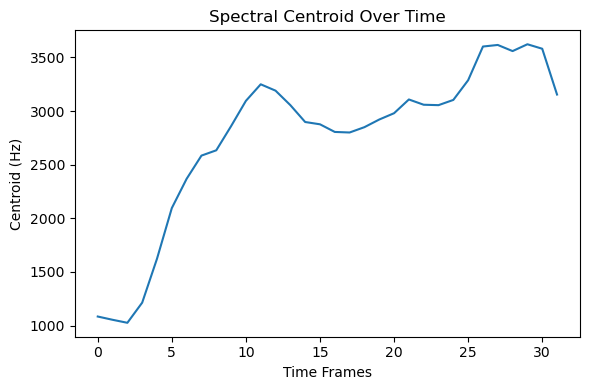

In [5]:
# Spectral Centroid

# audio file path
file_path = "dataset/normal/1 newborn crying_expiration.wav"

# load audio
y, sr = librosa.load(file_path, sr=None)

# extract spectral centroid
centroid = librosa.feature.spectral_centroid(y=y, sr=sr)

# plot
plt.figure(figsize=(6,4))
plt.plot(centroid[0])
plt.xlabel("Time Frames")
plt.ylabel("Centroid (Hz)")
plt.title("Spectral Centroid Over Time")
plt.tight_layout()
plt.show()

### **Spectral Centroid - Sepsis**

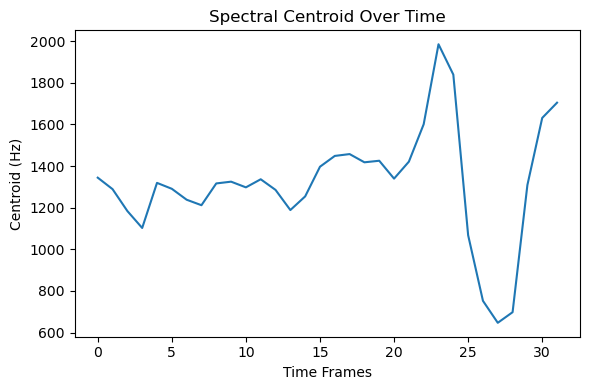

In [6]:
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration2.wav"

# load audio
y, sr = librosa.load(file_path, sr=None)

# extract spectral centroid
centroid = librosa.feature.spectral_centroid(y=y, sr=sr)

# plot
plt.figure(figsize=(6,4))
plt.plot(centroid[0])
plt.xlabel("Time Frames")
plt.ylabel("Centroid (Hz)")
plt.title("Spectral Centroid Over Time")
plt.tight_layout()
plt.show()

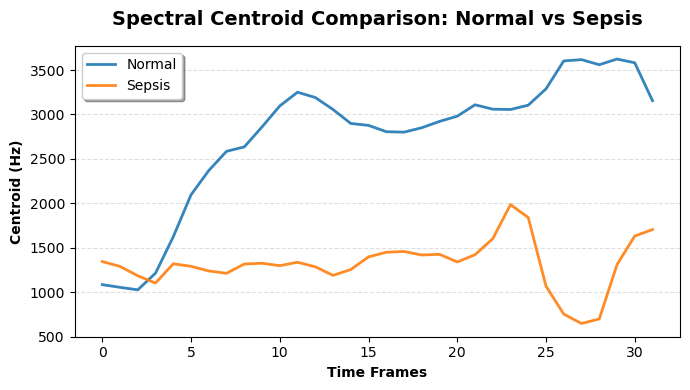

In [18]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

# 1. Load and Extract: Normal
file_path_normal = "dataset/normal/1 newborn crying_expiration.wav"
y_n, sr_n = librosa.load(file_path_normal, sr=None)
centroid_n = librosa.feature.spectral_centroid(y=y_n, sr=sr_n)[0] # Extract first row

# 2. Load and Extract: Sepsis
file_path_sepsis = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration2.wav"
y_s, sr_s = librosa.load(file_path_sepsis, sr=None)
centroid_s = librosa.feature.spectral_centroid(y=y_s, sr=sr_s)[0] # Extract first row

# 3. Create Superimposed Plot
plt.figure(figsize=(7, 4))

# Plotting with specified colors and labels
plt.plot(centroid_n, label='Normal', color='#1f77b4', linewidth=2, alpha=0.9)
plt.plot(centroid_s, label='Sepsis', color='#ff7f0e', linewidth=2, alpha=0.9)

# Thesis-grade Styling
plt.title("Spectral Centroid Comparison: Normal vs Sepsis", fontweight='bold', size=14, pad=15)
plt.xlabel("Time Frames", fontweight='bold')
plt.ylabel("Centroid (Hz)", fontweight='bold')

# Legend and Grid
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(visible=True, axis='y', linestyle='--', alpha=0.4)
plt.grid(visible=False, axis='x') # Remove vertical lines for a cleaner look

plt.tight_layout()
plt.savefig('spectral_centroid_comparison.pdf', dpi=300) # Save as PDF for thesis
plt.show()

### **RMS Energy - Normal**

(1, 32)


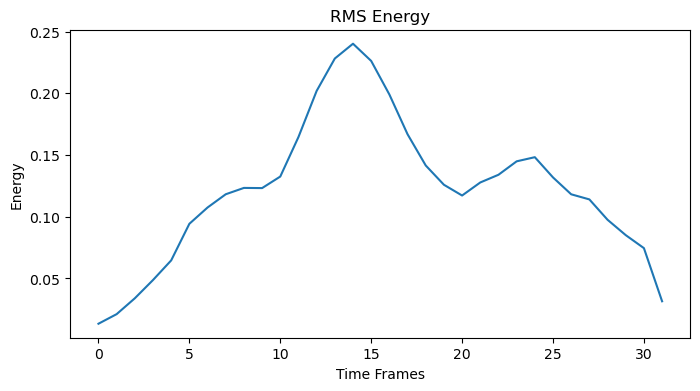

In [ ]:
# RMS Energy
# Normal
# audio file path
file_path = "dataset/normal/1 newborn crying_expiration.wav"

# load audio
y, sr = librosa.load(file_path, sr=16000)

rms = librosa.feature.rms(y=y)

print(rms.shape)

# Plot
plt.figure(figsize=(8,4))
plt.plot(rms[0])
plt.title("RMS Energy")
plt.xlabel("Time Frames")
plt.ylabel("Energy")
plt.show()

### **RMS Energy - Sepsis**

(1, 32)


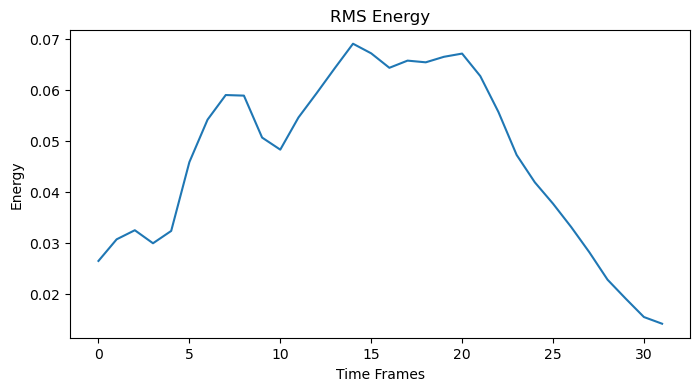

In [ ]:
# Sepsis
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav"

# load audio
y, sr = librosa.load(file_path, sr=16000)

rms = librosa.feature.rms(y=y)

print(rms.shape)

# Plot
plt.figure(figsize=(8,4))
plt.plot(rms[0])
plt.title("RMS Energy")
plt.xlabel("Time Frames")
plt.ylabel("Energy")
plt.show()

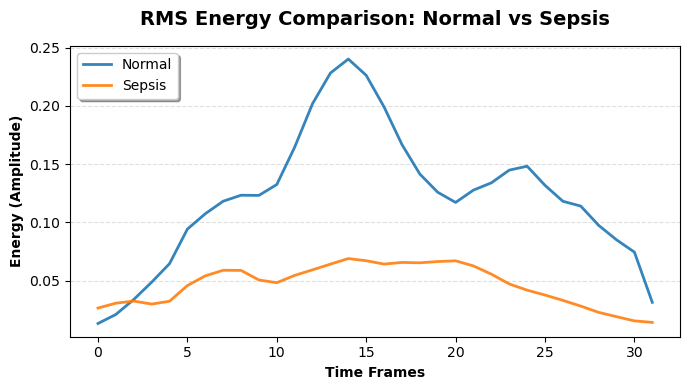

In [158]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

# 1. Extract RMS: Normal
file_path_n = "dataset/normal/1 newborn crying_expiration.wav"
y_n, sr_n = librosa.load(file_path_n, sr=16000)
rms_n = librosa.feature.rms(y=y_n)[0]

# 2. Extract RMS: Sepsis
file_path_s = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav"
y_s, sr_s = librosa.load(file_path_s, sr=16000)
rms_s = librosa.feature.rms(y=y_s)[0]

# 3. Create Superimposed Plot
plt.figure(figsize=(7, 4))

# Plotting with transparency (alpha) to see overlapping sections
plt.plot(rms_n, label='Normal', color='#1f77b4', linewidth=2, alpha=0.9)
plt.plot(rms_s, label='Sepsis', color='#ff7f0e', linewidth=2, alpha=0.9)

# Thesis-grade Styling
plt.title("RMS Energy Comparison: Normal vs Sepsis", fontweight='bold', size=14, pad=15)
plt.xlabel("Time Frames", fontweight='bold')
plt.ylabel("Energy (Amplitude)", fontweight='bold')

# Legend and Grid setup
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(visible=True, axis='y', linestyle='--', alpha=0.4)
plt.grid(visible=False, axis='x') # Keep vertical bars hidden for clarity

plt.tight_layout()
plt.savefig('rms_energy_comparison.pdf', dpi=300)
plt.show()

### **Pitch - Normal**

(32,)


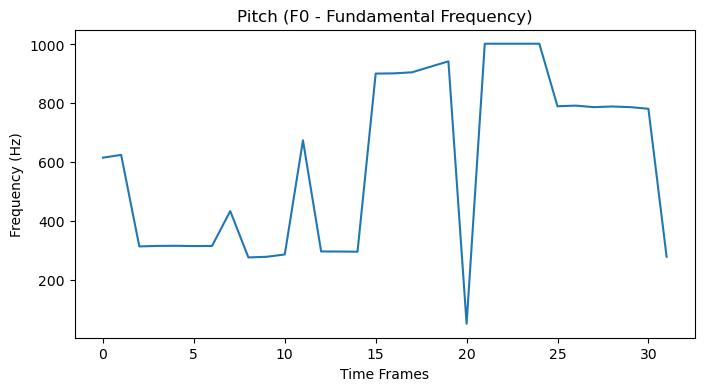

In [ ]:
# Pitch
# Normal
# audio file path
file_path = "dataset/normal/1 newborn crying_expiration.wav"

y, sr = librosa.load(file_path, sr=16000)

# Pitch extraction
f0 = librosa.yin(
    y,
    fmin=50,     # minimum frequency (baby cry ke liye adjust)
    fmax=1000    # max frequency
)

print(f0.shape)

# Plot
plt.figure(figsize=(8,4))
plt.plot(f0)
plt.title("Pitch (F0 - Fundamental Frequency)")
plt.xlabel("Time Frames")
plt.ylabel("Frequency (Hz)")
plt.show()

### **Pitch - Sepsis**

(32,)


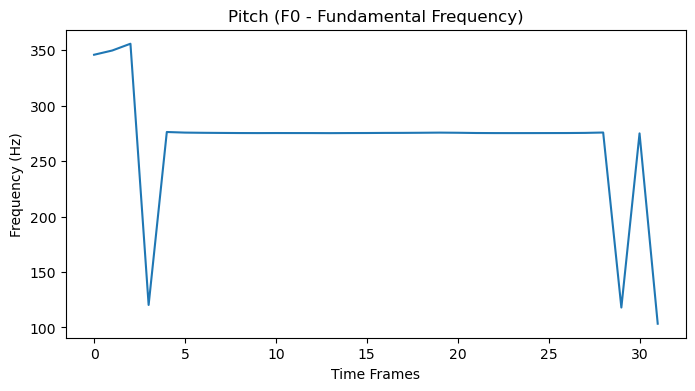

In [23]:
# Sepsis
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration1.wav"

y, sr = librosa.load(file_path, sr=16000)

# Pitch extraction
f0 = librosa.yin(
    y,
    fmin=50,     # minimum frequency (baby cry ke liye adjust)
    fmax=1000    # max frequency
)

print(f0.shape)

# Plot
plt.figure(figsize=(8,4))
plt.plot(f0)
plt.title("Pitch (F0 - Fundamental Frequency)")
plt.xlabel("Time Frames")
plt.ylabel("Frequency (Hz)")
plt.show()

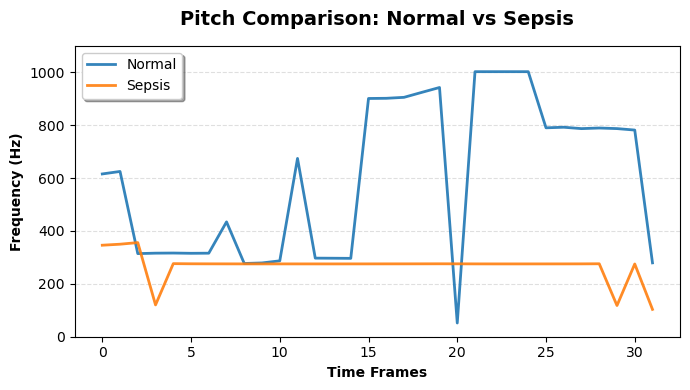

In [161]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

# Parameters
SR = 16000
FMIN = 50
FMAX = 1000

# 1. Extract Pitch: Normal
file_path_n = "dataset/normal/1 newborn crying_expiration.wav"
y_n, _ = librosa.load(file_path_n, sr=SR)
f0_n = librosa.yin(y_n, fmin=FMIN, fmax=FMAX)

# 2. Extract Pitch: Sepsis
file_path_s = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration1.wav"
y_s, _ = librosa.load(file_path_s, sr=SR)
f0_s = librosa.yin(y_s, fmin=FMIN, fmax=FMAX)

# 3. Create Superimposed Plot
plt.figure(figsize=(7, 4))

# Plotting Normal (Blue) and Sepsis (Orange)
plt.plot(f0_n, label='Normal', color='#1f77b4', linewidth=2, alpha=0.9)
plt.plot(f0_s, label='Sepsis', color='#ff7f0e', linewidth=2, alpha=0.9)

# Thesis-grade Styling
plt.title("Pitch Comparison: Normal vs Sepsis", fontweight='bold', size=14, pad=15)
plt.xlabel("Time Frames", fontweight='bold')
plt.ylabel("Frequency (Hz)", fontweight='bold')

# Setting Y-axis to focus on the human voice range
plt.ylim(0, 1100) 

# Legend and Grid
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(visible=True, axis='y', linestyle='--', alpha=0.4)
plt.grid(visible=False, axis='x') 

plt.tight_layout()
plt.savefig('pitch_f0_comparison.pdf', dpi=300)
plt.show()

### **Tempo & Beats - Normal**

Tempo: [170.45454545]
Beats (Frames): [ 5 16]
Beats (Times) : [0.16  0.512]
Number of beats detected: 2


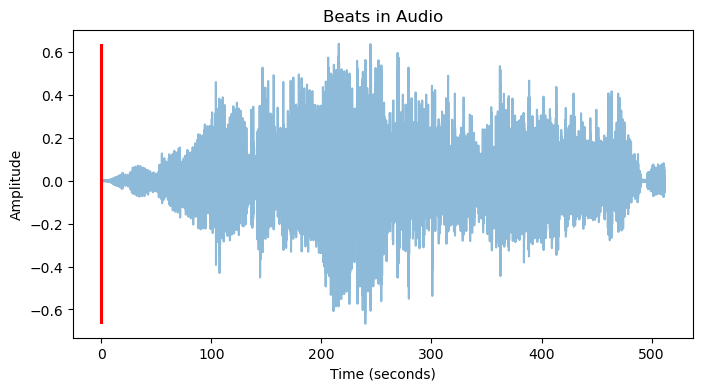

In [ ]:
# Tempo and Beats

# audio file path
file_path = "dataset/normal/1 newborn crying_expiration.wav"

y, sr = librosa.load(file_path, sr=16000)

# Beat tracking
tempo, beats = librosa.beat.beat_track(y=y, sr=sr)

print("Tempo:", tempo)
print("Beats (Frames):", beats[:10])

# Convert beat positions/frames to time
beat_times = librosa.frames_to_time(beats, sr=sr)

print("Beats (Times) :", beat_times[:10])
print("Number of beats detected:", len(beats))

# Understand output
# Tempo → single number (e.g., 120 BPM)
# Beats → array of positions (e.g., [100, 200, 300, ...]) in frames


# Plot 
plt.figure(figsize=(8,4))
times = librosa.times_like(y, sr=sr)
plt.plot(times, y, alpha=0.5)
plt.vlines(beat_times, ymin=min(y), ymax=max(y), color='r')
plt.title("Beats in Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

### **Tempo & Beats - Sepsis**

Tempo: [170.45454545]
Beats (Frames): [ 3 14 25]
Beats (Times) : [0.096 0.448 0.8  ]
Number of beats detected: 3


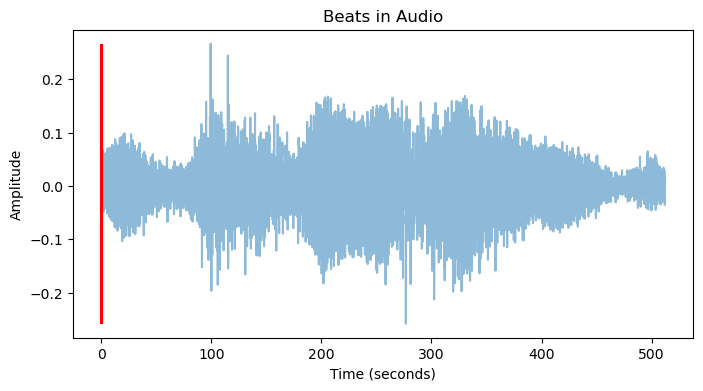

In [57]:
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav"

y, sr = librosa.load(file_path, sr=16000)

# Beat tracking
tempo, beats = librosa.beat.beat_track(y=y, sr=sr)

print("Tempo:", tempo)
print("Beats (Frames):", beats[:10])

# Convert beat positions/frames to time
beat_times = librosa.frames_to_time(beats, sr=sr)

print("Beats (Times) :", beat_times[:10])
print("Number of beats detected:", len(beats))


# Plot 
plt.figure(figsize=(8,4))
times = librosa.times_like(y, sr=sr)
plt.plot(times, y, alpha=0.5)
plt.vlines(beat_times, ymin=min(y), ymax=max(y), color='r')
plt.title("Beats in Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

### **ZCR - Normal**

(1, 32)


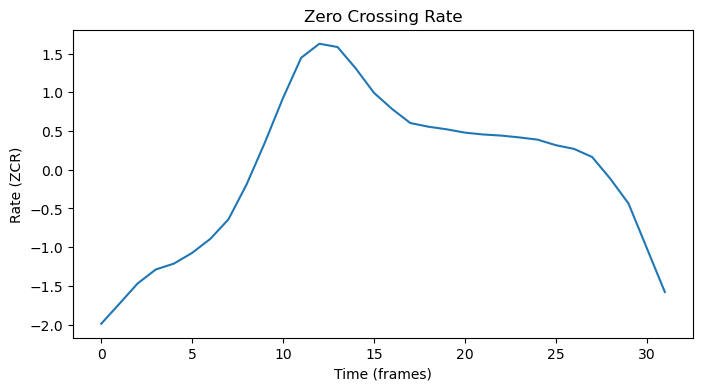

In [35]:
# Zero Crossing Rate (ZCR)
# Normal
# audio file path
file_path = "dataset/normal/1 newborn crying_expiration1.wav"

y, sr = librosa.load(file_path, sr=16000)

zcr = librosa.feature.zero_crossing_rate(y)

# Normalize ZCR
zcr = (zcr - np.mean(zcr)) / np.std(zcr)

print(zcr.shape)

# Plot
plt.figure(figsize=(8,4))
plt.plot(zcr[0])
plt.title("Zero Crossing Rate")
plt.xlabel("Time (frames)")
plt.ylabel("Rate (ZCR)")
plt.show()

### **ZCR - Sepsis**

(1, 32)


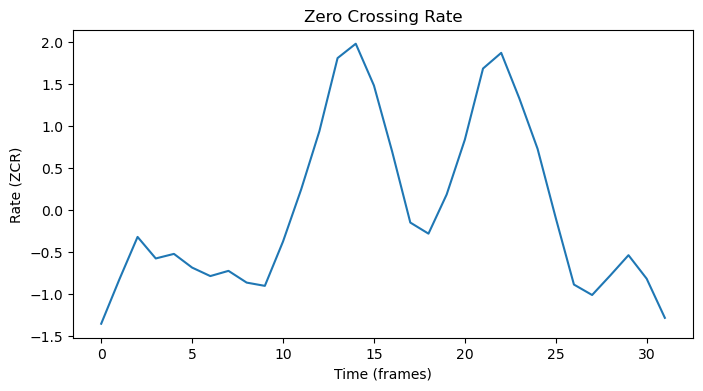

In [30]:
# Sepsis
# audio file path
file_path = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav"

y, sr = librosa.load(file_path, sr=16000)

zcr = librosa.feature.zero_crossing_rate(y)

# Normalize ZCR
zcr = (zcr - np.mean(zcr)) / np.std(zcr)

print(zcr.shape)

# Plot
plt.figure(figsize=(8,4))
plt.plot(zcr[0])
plt.title("Zero Crossing Rate")
plt.xlabel("Time (frames)")
plt.ylabel("Rate (ZCR)")
plt.show()

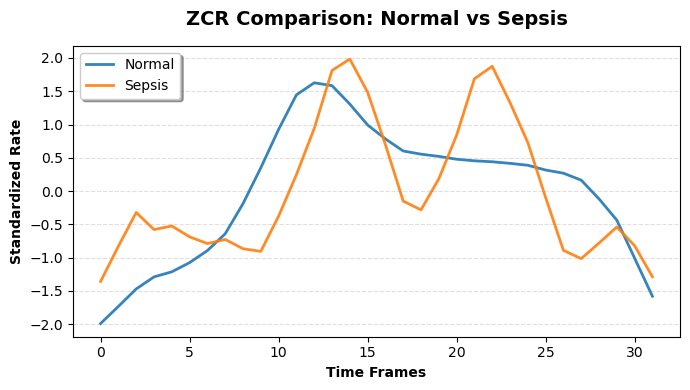

In [162]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

# 1. Process Normal Data
file_path_n = "dataset/normal/1 newborn crying_expiration1.wav"
y_n, sr_n = librosa.load(file_path_n, sr=16000)
zcr_n = librosa.feature.zero_crossing_rate(y_n)[0]
# Normalization (Standardization)
zcr_n_norm = (zcr_n - np.mean(zcr_n)) / np.std(zcr_n)

# 2. Process Sepsis Data
file_path_s = "dataset/sepsis/PA_HIE(III)_Sepsis_220915_1559_expiration.wav"
y_s, sr_s = librosa.load(file_path_s, sr=16000)
zcr_s = librosa.feature.zero_crossing_rate(y_s)[0]
# Normalization (Standardization)
zcr_s_norm = (zcr_s - np.mean(zcr_s)) / np.std(zcr_s)

# 3. Create Superimposed Plot
plt.figure(figsize=(7, 4))

# Plotting with transparency (alpha)
plt.plot(zcr_n_norm, label='Normal', color='#1f77b4', linewidth=2, alpha=0.9)
plt.plot(zcr_s_norm, label='Sepsis', color='#ff7f0e', linewidth=2, alpha=0.9)

# Thesis-grade Styling
plt.title("ZCR Comparison: Normal vs Sepsis", fontweight='bold', size=14, pad=15)
plt.xlabel("Time Frames", fontweight='bold')
plt.ylabel("Standardized Rate", fontweight='bold')

# Legend and Grid
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(visible=True, axis='y', linestyle='--', alpha=0.4)
plt.grid(visible=False, axis='x') 

plt.tight_layout()
plt.savefig('zcr_comparison.pdf', dpi=300)
plt.show()